# Halle2 (6G Rocket) - Sionna RT import check + 3D viewer

Source: `~/6grocket/Halle2.xml.zip` -> `Halle2.xml` + `meshes.7z` (extracted to `~/halle2-factory/scene/meshes`).
Mitsuba 3 XML exported from Blender (Mitsuba add-on), 6 shapes, ITU materials (`mat-itu_*` -> Sionna `ITURadioMaterial`).

**Preview controls**: left-drag rotate, scroll zoom, right-drag pan. The roof starts at z = 7.3 m, so previews clip at `CLIP_Z`.

In [1]:
import os, numpy as np, warnings
import sionna.rt as rt
import matplotlib.pyplot as plt
warnings.simplefilter("always")
SCENE = os.path.realpath("../scene/Halle2.xml")
print(SCENE)

/home/avivekan23/6grocket/halle2/Halle2.xml


## 1. Load and inspect (shapes kept separate so each mesh is visible)

In [2]:
scene = rt.load_scene(SCENE, merge_shapes=False)
scene.frequency = 3.85e9
b = scene.mi_scene.bbox(); print("scene bbox", np.round(np.array(b.min),1), np.round(np.array(b.max),1))
for n, o in scene.objects.items():
    bb = o.mi_mesh.bbox()
    print(f"{n:24s} {o.radio_material.name:18s} faces={o.mi_mesh.face_count():>8d}  min={np.round(np.array(bb.min),1)} max={np.round(np.array(bb.max),1)}")
for k, m in scene.radio_materials.items():
    print(f"{k:18s} eps_r={float(np.squeeze(m.relative_permittivity)):.2f}  sigma={float(np.squeeze(m.conductivity)):.4g} S/m @3.85 GHz")

2026-09-29 00:54:00 WARN  [HDRFilm] Monochrome mode enabled, setting film output pixel format to 'luminance' (was rgb).
scene bbox [-1.013e+02 -3.150e+01 -1.000e-01] [121.4 128.5  13. ]
Walls-itu_plasterboard   itu_plasterboard   faces=  160895  min=[-60.3 -22.8  -0. ] max=[ 94.  120.5  10.2]
Walls-itu_glass          itu_glass          faces=     168  min=[-29.9  45.1   1.5] max=[29.8 59.8 10. ]
Floor                    itu_concrete       faces=    8680  min=[-101.3  -31.5    0. ] max=[121.4 128.5   0. ]
Doors                    itu_glass          faces= 1325506  min=[-37.4 -23.   -0.1] max=[ 93.3 117.6   2.1]
Roof                     itu_ceiling_board  faces=  590352  min=[-57.4 -21.6   7.3] max=[ 90.7 120.1  13. ]
MetalStuff               itu_metal          faces= 3496550  min=[-57.1 -22.5  -0.1] max=[ 82.  119.9  11.3]
itu_plasterboard   eps_r=2.73  sigma=0.02758 S/m @3.85 GHz
itu_glass          eps_r=6.31  sigma=0.01928 S/m @3.85 GHz
itu_concrete       eps_r=5.24  sigma=0.1231 S/m 

## 2. Interactive 3D view

In [3]:
CLIP_Z = 7.0   # m; roof spans z = 7.3 - 13 m
scene.preview(clip_at=CLIP_Z, clip_plane_orientation=(0, 0, -1))

## 3. Optional: TX + radio map (sanity check that ray tracing works)

TX below the roof. Edit `TX_POS` / `TX_DBM`. Note: 5.6 M faces (MetalStuff 3.5 M, Doors 1.3 M) - fine on the GPU.

2026-09-29 00:57:04 WARN  [HDRFilm] Monochrome mode enabled, setting film output pixel format to 'luminance' (was rgb).
coverage 80% of cells | RSS dBm min -120.3 median -61.3 max -29.9


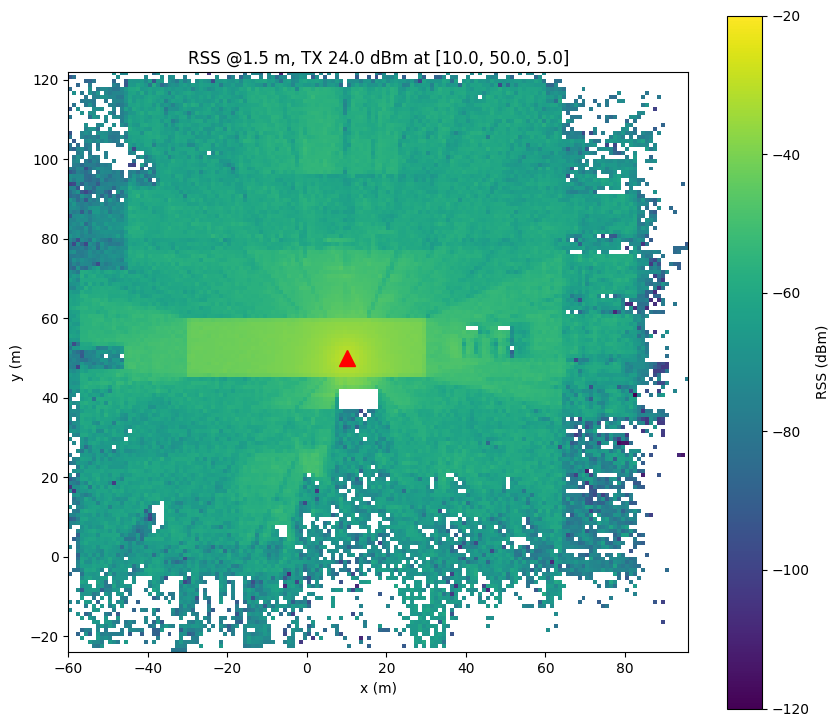

In [ ]:
TX_POS, TX_DBM = [10.0, 50.0, 5.0], 15.0
scene = rt.load_scene(SCENE, merge_shapes=True)       # fresh scene so re-running doesn't duplicate the TX
scene.frequency, scene.bandwidth = 3.85e9, 20e6
scene.tx_array = rt.PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = scene.tx_array
scene.add(rt.Transmitter("tx", position=TX_POS, power_dbm=TX_DBM))
CENTER, SIZE = [18, 49, 1.5], [156, 146]
rm = rt.RadioMapSolver()(scene, cell_size=(1.0, 1.0), samples_per_tx=int(1e7), max_depth=6, refraction=True,
                         center=CENTER, orientation=[0, 0, 0], size=SIZE)
rss_dbm = 10*np.log10(np.maximum(np.array(rm.rss)[0], 1e-30)) + 30
ok = rss_dbm > -250
print(f"coverage {ok.mean()*100:.0f}% of cells | RSS dBm min {rss_dbm[ok].min():.1f} median {np.median(rss_dbm[ok]):.1f} max {rss_dbm[ok].max():.1f}")
ext = [CENTER[0]-SIZE[0]/2, CENTER[0]+SIZE[0]/2, CENTER[1]-SIZE[1]/2, CENTER[1]+SIZE[1]/2]
plt.figure(figsize=(10, 9)); plt.imshow(np.where(ok, rss_dbm, np.nan), origin="lower", extent=ext, cmap="viridis", vmin=-120, vmax=-20)
plt.colorbar(label="RSS (dBm)"); plt.plot(TX_POS[0], TX_POS[1], "r^", ms=12); plt.xlabel("x (m)"); plt.ylabel("y (m)")
plt.title(f"RSS @1.5 m, TX {TX_DBM} dBm at {TX_POS}"); plt.show()
scene.preview(radio_map=rm, rm_metric="rss", clip_at=CLIP_Z, clip_plane_orientation=(0, 0, -1))

## 4. SNR radio map rendered on the 3D scene

Sionna's `rm_metric="sinr"` = RSS / (interference + k·T·B). With one TX there is no interference, so SINR = SNR.
Noise is taken from `scene.temperature` and `scene.bandwidth` **at solve time**, so set them before calling the solver.
The UE noise figure goes in by raising the temperature: T = 290·10^(NF/10).

In [ ]:
TX_POS, TX_DBM = [10.0, 50.0, 5.0], 15.0
BW, NF_DB = 20e6, 9.0                                   # bandwidth (Hz), UE noise figure (dB)
RX_Z = 1.5                                               # height of the SNR plane (m)
SNR_VMIN, SNR_VMAX = -10, 60                             # colour-scale limits (dB)

scene = rt.load_scene(SCENE, merge_shapes=True)          # fresh scene so re-running doesn't duplicate the TX
scene.frequency, scene.bandwidth = 3.85e9, BW
scene.temperature = 290 * 10**(NF_DB/10)                 # noise = k*T*B incl. NF
scene.tx_array = rt.PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
scene.rx_array = scene.tx_array
scene.add(rt.Transmitter("tx", position=TX_POS, power_dbm=TX_DBM))
CENTER, SIZE = [18, 49, RX_Z], [156, 146]
rm = rt.RadioMapSolver()(scene, cell_size=(1.0, 1.0), samples_per_tx=int(1e7), max_depth=6, refraction=True,
                         center=CENTER, orientation=[0, 0, 0], size=SIZE)

noise_dbm = 10*np.log10(float(np.squeeze(scene.thermal_noise_power))) + 30
snr_db = 10*np.log10(np.maximum(np.array(rm.sinr)[0], 1e-30)); ok = snr_db > -200
print(f"noise floor {noise_dbm:.1f} dBm | SNR dB: min {snr_db[ok].min():.1f}  median {np.median(snr_db[ok]):.1f}  max {snr_db[ok].max():.1f}")

scene.preview(radio_map=rm, rm_metric="sinr", rm_vmin=SNR_VMIN, rm_vmax=SNR_VMAX,
              clip_at=CLIP_Z, clip_plane_orientation=(0, 0, -1))